## Análise Exploratória

Objetivo: entender a estrutura do dataset, a relação das variáveis com a compra (`Revenue`) e tomar decisões de pré-processamento para o pipeline de Random Forest.

**Roteiro**
1. Carga e visão geral
2. Qualidade dos dados (nulos, duplicatas, tipos)
3. Variável-alvo
4. Variáveis numéricas (distribuição, relação com o alvo, correlação)
5. Variáveis categóricas (taxa de conversão por categoria)
6. Deep dive em `PageValues`, `BounceRates` e `ExitRates`
7. Testes estatísticos e informação mútua
8. Conclusões e decisões para o pipeline

### Setup e Carga dos dados

In [15]:
# Importar Bibliotecas e Configuração
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

caminho_dataset = '..\datasets\online_shoppers_intention.csv'
TARGET = "Revenue"

NUMERIC_COLS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
CATEGORICAL_COLS = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType",
]
BINARY_COLS = ["Weekend"]
# Importar
df_raw = pd.read_csv(caminho_dataset)

<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:11: SyntaxWarning: invalid escape sequence '\d'
C:\Users\User\AppData\Local\Temp\ipykernel_18072\3104141197.py:11: SyntaxWarning: invalid escape sequence '\d'
  caminho_dataset = '..\datasets\online_shoppers_intention.csv'


### Visão Geral dos dados

In [16]:
display(df_raw.dtypes.to_frame("dtype").join(df_raw.nunique().to_frame("n_unicos")))

print("\nValores nulos por coluna")
nulls = df_raw.isna().sum()
print(nulls[nulls > 0] if nulls.any() else "Nenhum valor nulo.")

n_dup = df_raw.duplicated().sum()
print(f"\nLinhas duplicadas: {n_dup} ({n_dup / len(df_raw):.2f})")

,dtype,n_unicos
Administrative,int64,27
Administrative_Duration,float64,3335
Informational,int64,17
Informational_Duration,float64,1258
ProductRelated,int64,311
ProductRelated_Duration,float64,9551
BounceRates,float64,1872
ExitRates,float64,4777
PageValues,float64,2704
SpecialDay,float64,6



Valores nulos por coluna
Nenhum valor nulo.

Linhas duplicadas: 125 (0.01)


In [17]:
# Limpeza básica: remove duplicatas e ajusta tipos
df = df_raw.drop_duplicates().reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)
df['Weekend'] = df["Weekend"].astype(int)
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype(str)

print(f"Shape após limpeza: {df.shape}")
display(df[NUMERIC_COLS].describe().T)

Shape após limpeza: (12205, 18)


,count,mean,std,min,25%,50%,75%,max
Administrative,"12,205.0000",2.3389,3.3304,0.0000,0.0000,1.0000,4.0000,27.0000
Administrative_Duration,"12,205.0000",81.6463,177.4918,0.0000,0.0000,9.0000,94.7000,"3,398.7500"
Informational,"12,205.0000",0.5087,1.2756,0.0000,0.0000,0.0000,0.0000,24.0000
Informational_Duration,"12,205.0000",34.8255,141.4248,0.0000,0.0000,0.0000,0.0000,"2,549.3750"
ProductRelated,"12,205.0000",32.0456,44.5936,0.0000,8.0000,18.0000,38.0000,705.0000
ProductRelated_Duration,"12,205.0000","1,206.9825","1,919.6014",0.0000,193.0000,608.9429,"1,477.1548","63,973.5222"
BounceRates,"12,205.0000",0.0204,0.0453,0.0000,0.0000,0.0029,0.0167,0.2000
ExitRates,"12,205.0000",0.0415,0.0462,0.0000,0.0142,0.0250,0.0485,0.2000
PageValues,"12,205.0000",5.9496,18.6537,0.0000,0.0000,0.0000,0.0000,361.7637
SpecialDay,"12,205.0000",0.0619,0.1997,0.0000,0.0000,0.0000,0.0000,1.0000


**Obs**: muitas variáveis de contagem/duração são zero-inflated (muitas sessões sem visita a páginas administrativas/informativas), por isso médias bem diferentes das medianas

### Variável alvo

Revenue
0    10297
1     1908

Taxa de conversão: 15.63%  |  Razão neg:pos = 5.4:1


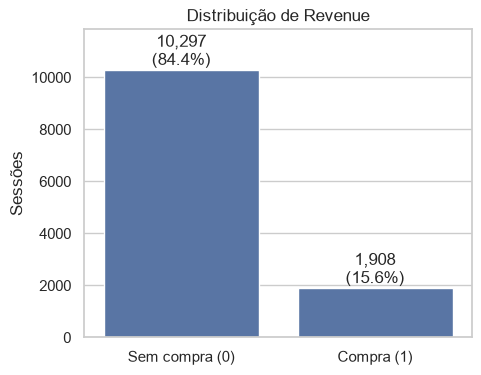

In [18]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()
print(counts.to_string())
print(f"\nTaxa de conversão: {rate:.2%}  |  Razão neg:pos = {counts[0] / counts[1]:.1f}:1")

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Sem compra (0)", "Compra (1)"], y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Sessões")
ax.set_title("Distribuição de Revenue")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

O desbalanceamento é forte. No treino isso justifica `class_weight`, métricas como PR-AUC/F1 e ajuste de limiar, em vez de acurácia.

### Variáveis Númericas

#### Distribuições

,% zeros
SpecialDay,89.8%
Informational_Duration,80.3%
Informational,78.4%
PageValues,77.6%
Administrative_Duration,47.3%
Administrative,46.2%
BounceRates,45.2%
ProductRelated_Duration,5.2%
ExitRates,0.6%
ProductRelated,0.3%


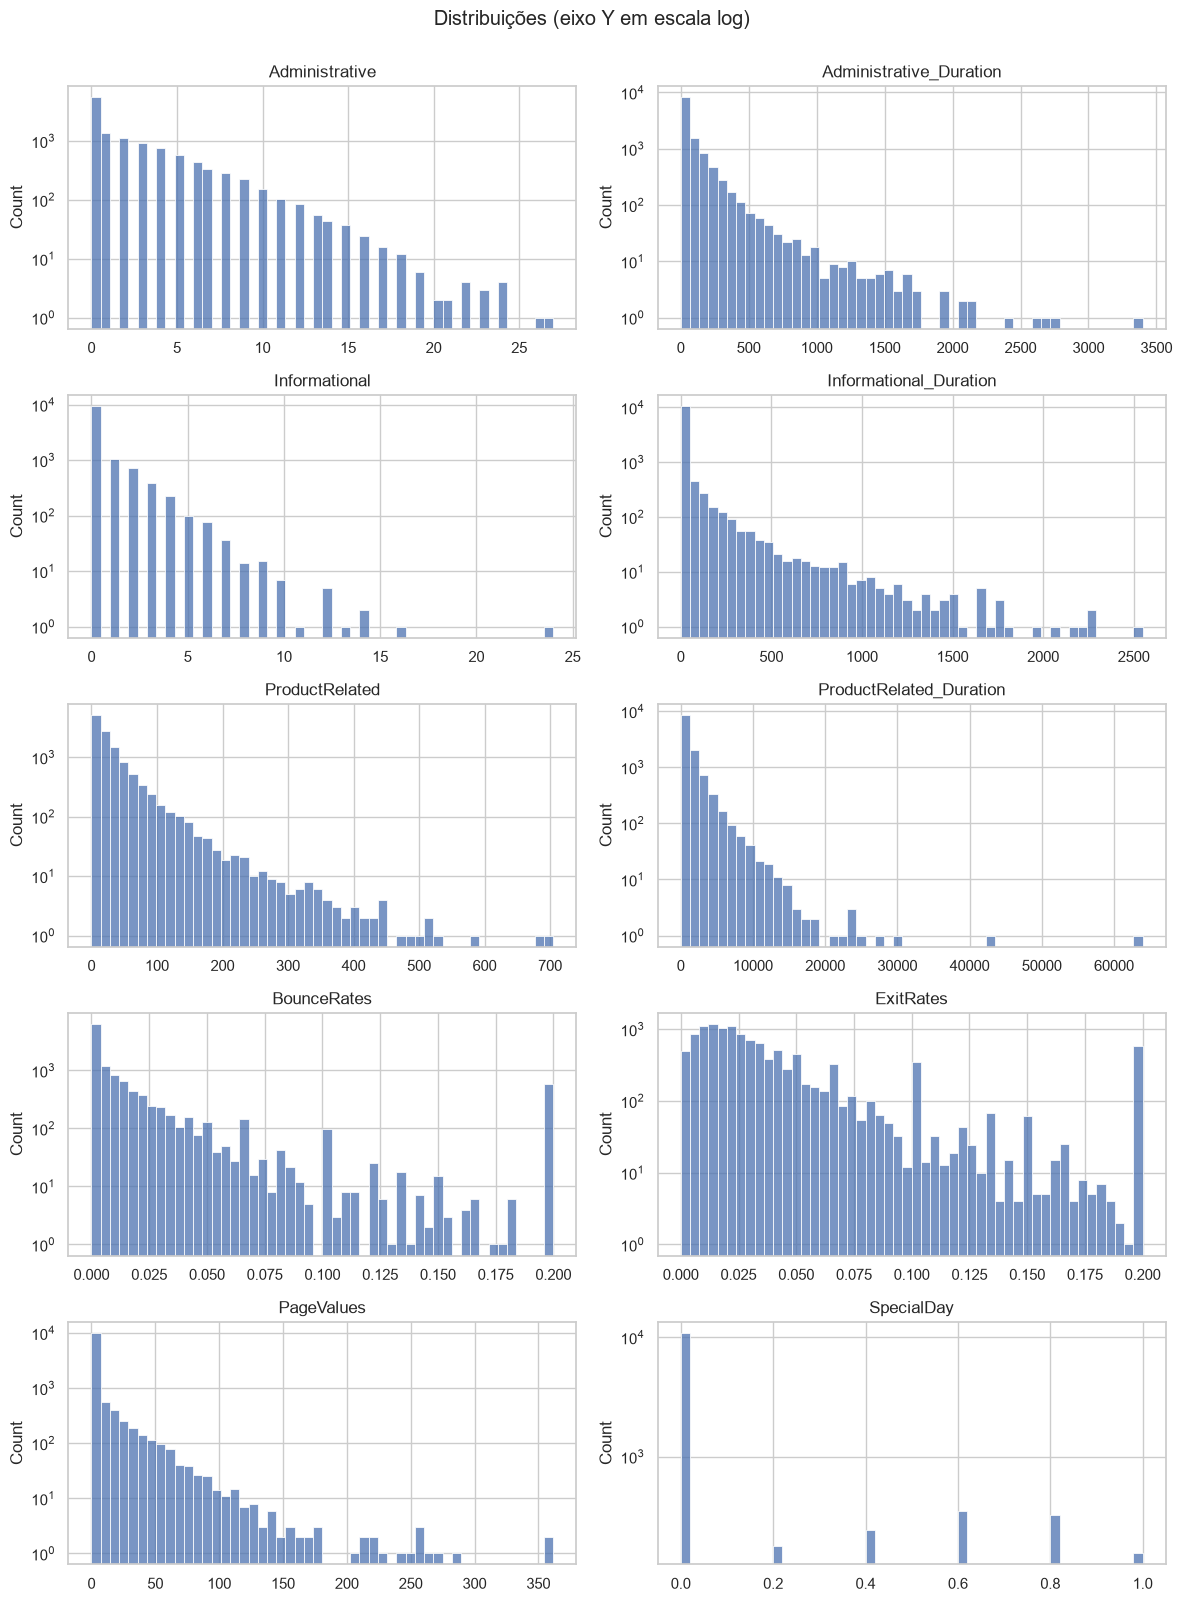

In [19]:
zero_share = (df[NUMERIC_COLS] == 0).mean().sort_values(ascending=False)
display(zero_share.to_frame("% zeros").style.format("{:.1%}"))

fig, axes = plt.subplots(5, 2, figsize=(12, 16))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribuições (eixo Y em escala log)", y=1.0)
plt.tight_layout()
plt.show()

#### Caldas e valores extremos

In [20]:
q = df[NUMERIC_COLS].quantile([0.5, 0.9, 0.99, 1.0]).T
q.columns = ["p50", "p90", "p99", "max"]
q["max/p99"] = q["max"] / q["p99"].replace(0, np.nan)
display(q)

,p50,p90,p99,max,max/p99
Administrative,1.0000,7.0000,14.0000,27.0000,1.9286
Administrative_Duration,9.0000,227.0000,838.7049,"3,398.7500",4.0524
Informational,0.0000,2.0000,6.0000,24.0000,4.0000
Informational_Duration,0.0000,73.9000,722.3792,"2,549.3750",3.5291
ProductRelated,18.0000,74.0000,221.0000,705.0000,3.1900
ProductRelated_Duration,608.9429,"2,904.4591","8,704.2716","63,973.5222",7.3497
BounceRates,0.0029,0.0500,0.2000,0.2000,1.0000
ExitRates,0.0250,0.1000,0.2000,0.2000,1.0000
PageValues,0.0000,19.1141,86.1087,361.7637,4.2012
SpecialDay,0.0000,0.2000,1.0000,1.0000,1.0000


Caudas longas são esperadas em dados de navegação. Para Random Forest isso não exige transformação nem remoção de outliers (o modelo é invariante a transformações monotônicas), então a recomendação é **mantê-los**

#### Numéricas x alvo

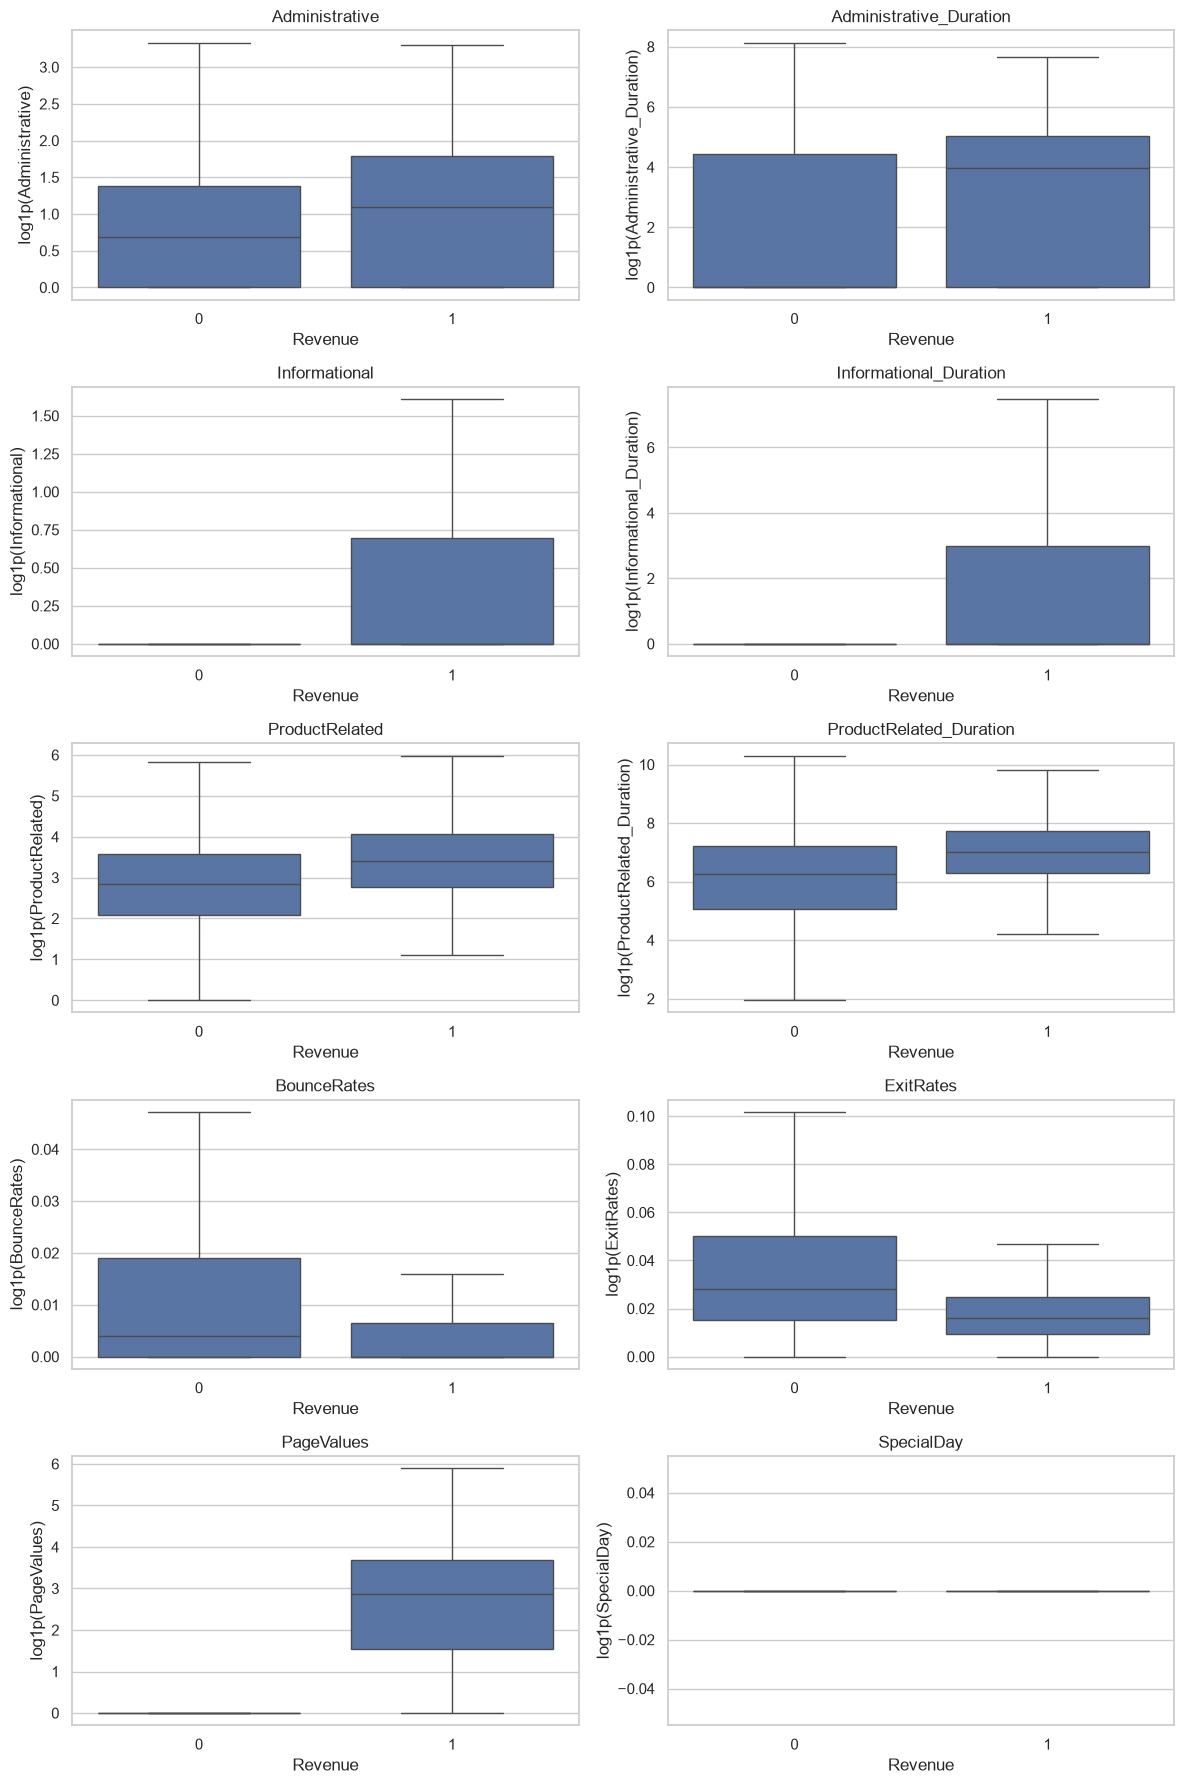

Revenue,mediana (sem compra),mediana (compra)
Administrative,1.0000,2.0000
Administrative_Duration,0.0000,52.3667
Informational,0.0000,0.0000
Informational_Duration,0.0000,0.0000
ProductRelated,16.0000,29.0000
ProductRelated_Duration,526.0000,"1,109.9062"
BounceRates,0.0039,0.0000
ExitRates,0.0284,0.0160
PageValues,0.0000,16.7581
SpecialDay,0.0000,0.0000


In [22]:
fig, axes = plt.subplots(5, 2, figsize=(12, 18))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.boxplot(x=df[TARGET], y=np.log1p(df[col]), ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_ylabel(f"log1p({col})")
    ax.set_xlabel("Revenue")
plt.tight_layout()
plt.show()

display(df.groupby(TARGET)[NUMERIC_COLS].median().T.rename(columns={0: "mediana (sem compra)", 1: "mediana (compra)"}))

#### Correlação (Spearman)

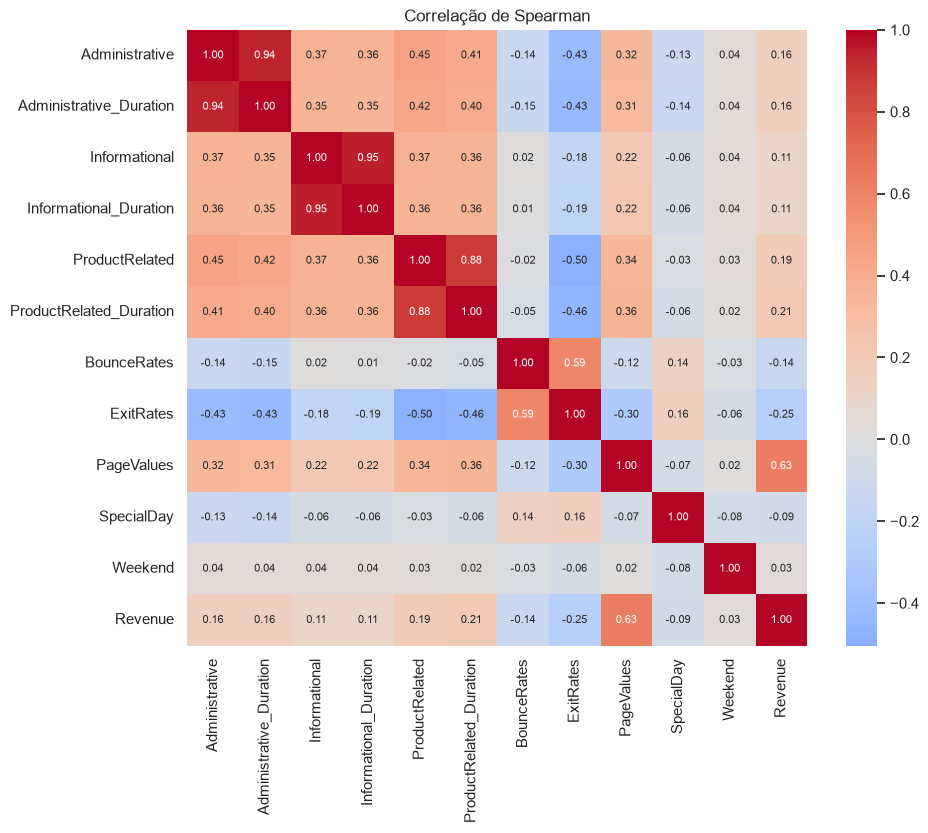

Correlação com Revenue:


,spearman
PageValues,0.6257
ExitRates,-0.2510
ProductRelated_Duration,0.2127
ProductRelated,0.1943
Administrative,0.1645
Administrative_Duration,0.1605
BounceRates,-0.1436
Informational,0.1119
Informational_Duration,0.1102
SpecialDay,-0.0883



Pares de features com |corr| >= 0.7:


,level_0,level_1,corr
25,Informational,Informational_Duration,0.9508
1,Administrative,Administrative_Duration,0.9393
49,ProductRelated,ProductRelated_Duration,0.8792


In [23]:
corr = df[NUMERIC_COLS + BINARY_COLS + [TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlação de Spearman")
plt.show()

print("Correlação com Revenue:")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("spearman"))

# Pares muito correlacionados entre as features (multicolinearidade)
pairs = (corr.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(corr) - 1,) * 2), k=1).astype(bool))
         .stack().rename("corr").reset_index())
pairs = pairs[pairs["corr"].abs() >= 0.7].sort_values("corr", key=abs, ascending=False)
print("\nPares de features com |corr| >= 0.7:")
display(pairs if len(pairs) else "Nenhum")

Esperamos alta correlação entre contagem e duração do mesmo tipo de página (ex.: `ProductRelated` e `ProductRelated_Duration`) e entre `BounceRates` e `ExitRates`. Para Random Forest a colinearidade não prejudica a predição, mas **dilui e distorce as importâncias**, o que vale lembrar na hora de interpretar.

### Variáveis categóricas

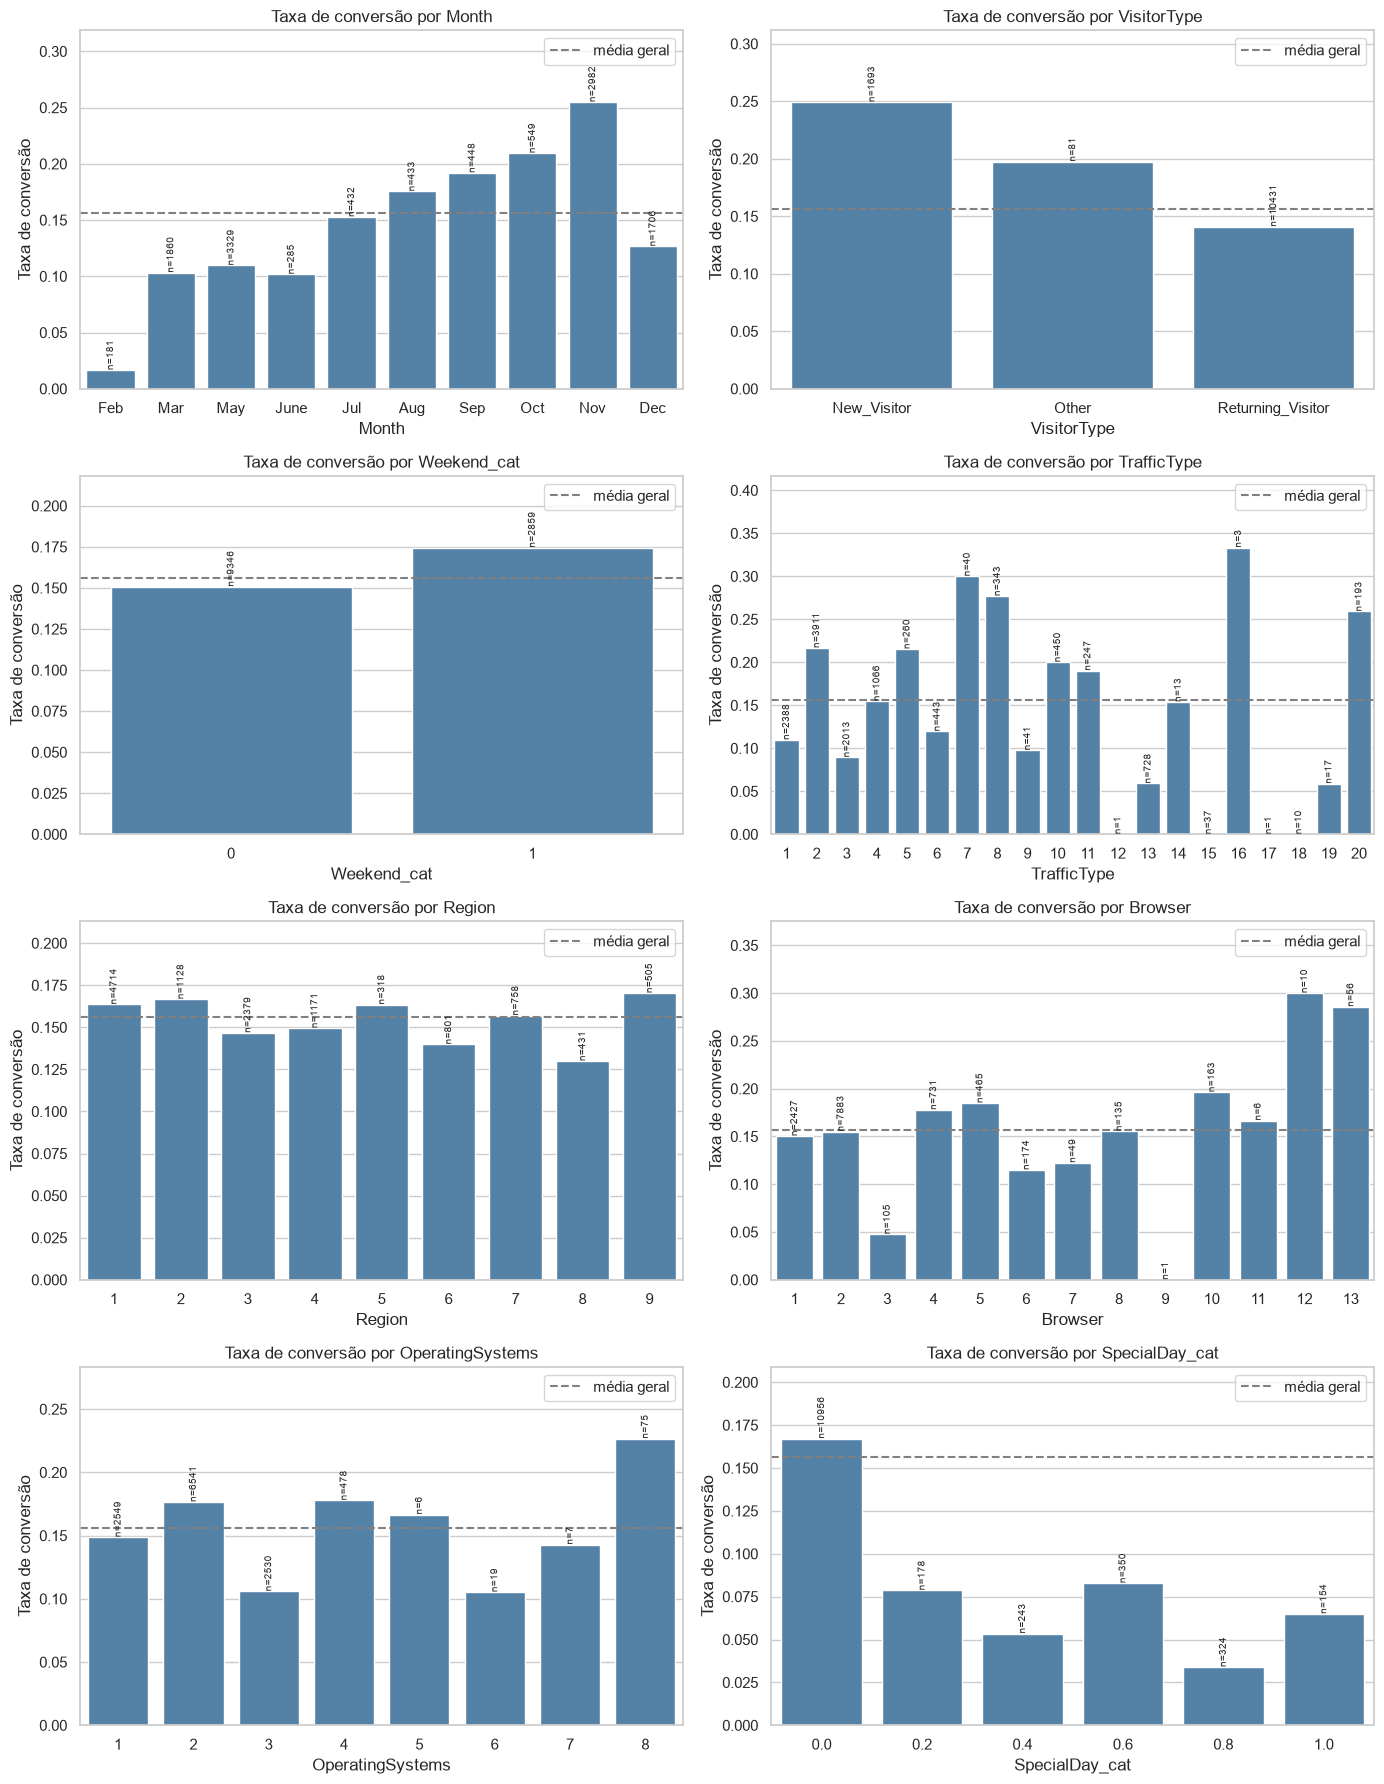

In [24]:
MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def sort_key(v):
    try:
        return (0, float(v))
    except ValueError:
        return (1, v)

def plot_rate_by_category(col, ax, order=None):
    g = df.groupby(col)[TARGET].agg(rate="mean", n="size").reset_index()
    if order is None:
        order = sorted(g[col].unique(), key=sort_key)
    g[col] = pd.Categorical(g[col], categories=[o for o in order if o in set(g[col])], ordered=True)
    g = g.sort_values(col)
    sns.barplot(data=g, x=col, y="rate", ax=ax, color="steelblue")
    ax.axhline(df[TARGET].mean(), ls="--", color="gray", label="média geral")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, r, f"n={n}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_title(f"Taxa de conversão por {col}")
    ax.set_ylabel("Taxa de conversão")
    ax.set_ylim(0, g["rate"].max() * 1.25)
    ax.legend()

cat_plots = [
    ("Month", MONTH_ORDER), ("VisitorType", None), ("Weekend", None),
    ("TrafficType", None), ("Region", None), ("Browser", None),
    ("OperatingSystems", None), ("SpecialDay", None),
]
df["SpecialDay"] = df["SpecialDay"].astype(float)

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, (col, order) in zip(axes.ravel(), cat_plots):
    tmp_col = col
    if col in ("Weekend", "SpecialDay"):
        df[col + "_cat"] = df[col].astype(str)
        tmp_col = col + "_cat"
    plot_rate_by_category(tmp_col, ax, order)
plt.tight_layout()
plt.show()
df.drop(columns=["Weekend_cat", "SpecialDay_cat"], inplace=True)

In [25]:
print("Contagem de sessões por mês (verifique os meses ausentes):")
display(df["Month"].value_counts().reindex([m for m in MONTH_ORDER]).to_frame("sessoes"))

print("Cardinalidade das categóricas:")
display(df[CATEGORICAL_COLS].nunique().to_frame("n_categorias"))

Contagem de sessões por mês (verifique os meses ausentes):


,sessoes
Month,
Jan,NaN
Feb,181.0000
Mar,"1,860.0000"
Apr,NaN
May,"3,329.0000"
June,285.0000
Jul,432.0000
Aug,433.0000
Sep,448.0000


Cardinalidade das categóricas:


,n_categorias
Month,10
OperatingSystems,8
Browser,13
Region,9
TrafficType,20
VisitorType,3


### PageValues,BounceRates e ExitRates

In [26]:
df["PageValues_zero"] = df["PageValues"] == 0
display(df.groupby("PageValues_zero")[TARGET].agg(taxa_conversao="mean", sessoes="size"))

pos = df[df["PageValues"] > 0].copy()
pos["faixa"] = pd.qcut(pos["PageValues"], q=5, duplicates="drop")
display(pos.groupby("faixa", observed=True)[TARGET].agg(taxa_conversao="mean", sessoes="size"))

,taxa_conversao,sessoes
PageValues_zero,,
False,0.5634,2730
True,0.0391,9475


,taxa_conversao,sessoes
faixa,,
"(0.037, 5.763]",0.3535,546
"(5.763, 12.134]",0.4414,546
"(12.134, 21.598]",0.5549,546
"(21.598, 41.716]",0.6593,546
"(41.716, 361.764]",0.8077,546


`PageValues` mede o valor médio das páginas visitadas antes da transação (Google Analytics). Se a taxa de conversão com `PageValues == 0` for muito baixa e subir fortemente nas faixas positivas, a variável é quase um *proxy* do alvo. Vale treinar o modelo **com e sem** ela e comparar, principalmente se o objetivo for prever durante a sessão.

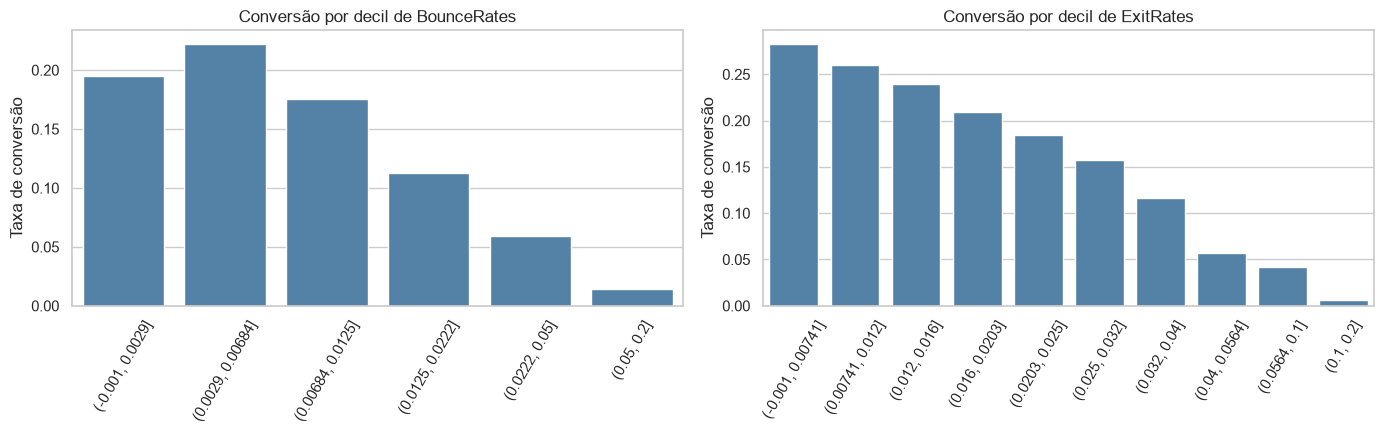

In [27]:
def rate_by_quantile(col, q=10):
    tmp = df[[col, TARGET]].copy()
    tmp["faixa"] = pd.qcut(tmp[col], q=q, duplicates="drop")
    return tmp.groupby("faixa", observed=True)[TARGET].agg(rate="mean", n="size").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["BounceRates", "ExitRates"]):
    g = rate_by_quantile(col)
    sns.barplot(data=g, x=g["faixa"].astype(str), y="rate", ax=ax, color="steelblue")
    ax.set_title(f"Conversão por decil de {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Taxa de conversão")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()